In [3]:
pip install "numpy<2" --force-reinstall

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
    --------------------------------------- 0.3/15.5 MB ? eta -:--:--
   ---- ----------------------------------- 1.6/15.5 MB 4.0 MB/s eta 0:00:04
   ----- ---------------------------------- 2.1/15.5 MB 4.9 MB/s eta 0:00:03
   --------- ------------------------------ 3.7/15.5 MB 4.5 MB/s eta 0:00:03
   ---------- ----------------------------- 3.9/15.5 MB 4.5 MB/s eta 0:00:03
   -------------------- ------------------- 8.1/15.5 MB 6.6 MB/s eta 0:00:02
   ------------------------- -------------- 9.7/15.5 MB 6.6 MB/s eta 0:00:01
   ----------------------------- ---------- 11.3/15.5 MB 6.8 MB/s eta 0:00:01
   --------------------------------- ------ 12.8/15.5 MB 6.9 MB/s eta 0:00:01
   ------------------------------------- -- 14.7/15.5 MB 7.1 MB/s eta 0:00:01
   -------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.


In [2]:
pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
 
OUT = "output_2d_transformations"
os.makedirs(OUT, exist_ok=True)

# Question 1: Image Transformations

### 2D Transformations

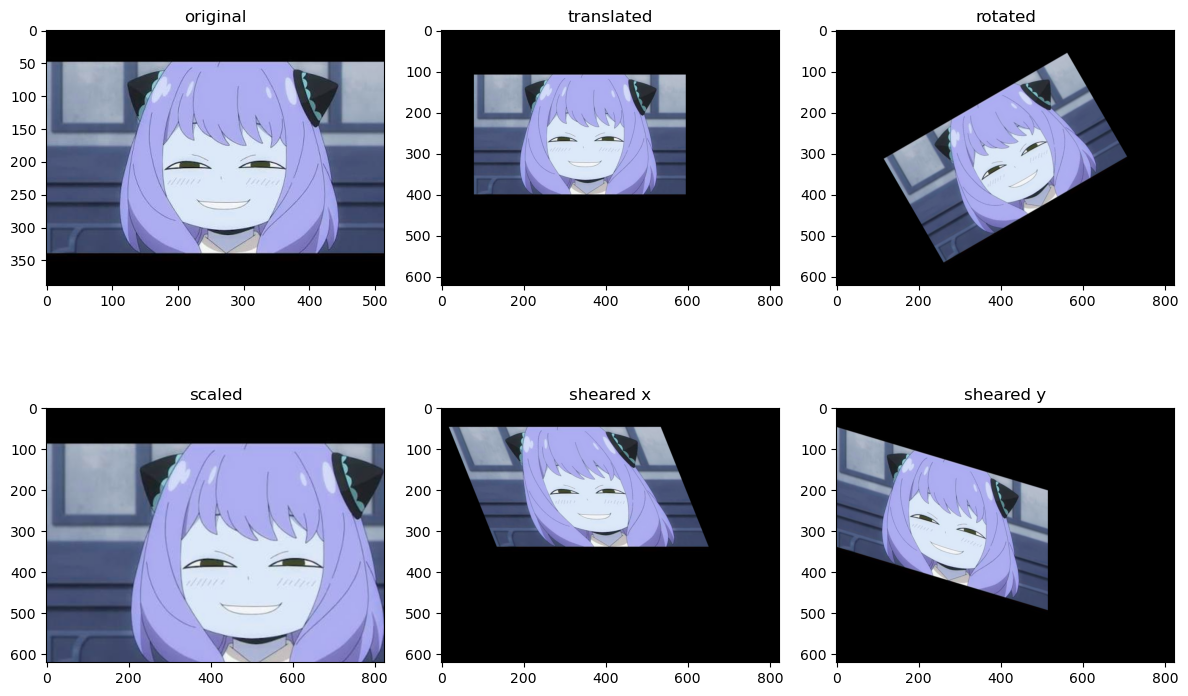

True

In [13]:
img = cv2.imread("sample.jpeg", cv2.COLOR_BGR2RGB)

# 2d transformation
h, w = img.shape[:2]
canvas = (int(w * 1.6), int(h * 1.6))  # bigger canvas so nothing is cut off
 
# Translation: shift by (tx, ty)
tx, ty = 80, 60
M_t = np.float32([[1, 0, tx],[0, 1, ty]])
translated = cv2.warpAffine(img, M_t, canvas)
 
# Rotation: about image centre by 30 degrees
M_r = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)
M_r[:, 2] += [(canvas[0] - w) / 2, (canvas[1] - h) / 2]  # recentre
rotated = cv2.warpAffine(img, M_r, canvas)
 
# Scaling: 1.4x in x, 0.7x in y (non-uniform)
sx, sy = 1.85, 1.85
M_s = np.float32([[sx, 0, 0], [0, sy, 0]])
scaled = cv2.warpAffine(img, M_s, canvas)
 
# Shearing: horizontal shear and vertical shear
shx, shy = 0.4, 0.3
M_shx = np.float32([[1, shx, 0],[0, 1, 0]])
M_shy = np.float32([[1, 0, 0],[shy, 1, 0]])
sheared_x = cv2.warpAffine(img, M_shx, canvas)
sheared_y = cv2.warpAffine(img, M_shy, canvas)

plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(img)
plt.title("original")

plt.subplot(2, 3, 2)
plt.imshow(translated)
plt.title("translated")

plt.subplot(2, 3, 3)
plt.imshow(rotated)
plt.title("rotated")

plt.subplot(2, 3, 4)
plt.imshow(scaled)
plt.title("scaled")

plt.subplot(2, 3, 5)
plt.imshow(sheared_x)
plt.title("sheared x")

plt.subplot(2, 3, 6)
plt.imshow(sheared_y)
plt.title("sheared y")

plt.tight_layout()
plt.show()

cv2.imwrite(os.path.join(OUT, "rotated.jpg"), rotated)
cv2.imwrite(os.path.join(OUT, "translated.jpg"), translated)
cv2.imwrite(os.path.join(OUT, "scaled.jpg"), scaled)
cv2.imwrite(os.path.join(OUT, "sheared_x.jpg"), sheared_x)
cv2.imwrite(os.path.join(OUT, "sheared_y.jpg"), sheared_y)

### 3D Transformation

In [14]:
OUT2 = "output_3d_transformations"
os.makedirs(OUT2, exist_ok=True)

In [15]:
img = cv2.imread("sample.jpeg", cv2.COLOR_BGR2RGB)
img = img[48:340, :]

In [16]:
h, w = img.shape[:2]

# rotation matrices about x, y and z (angles in degrees)
def rotate_x(a):
    a = np.radians(a)
    return np.array([[1, 0, 0],
                     [0, np.cos(a), -np.sin(a)],
                     [0, np.sin(a), np.cos(a)]])
 
 
def rotate_y(a):
    a = np.radians(a)
    return np.array([[np.cos(a), 0, np.sin(a)],
                     [0, 1, 0],
                     [-np.sin(a), 0, np.cos(a)]])
 
 
def rotate_z(a):
    a = np.radians(a)
    return np.array([[np.cos(a), -np.sin(a), 0],
                     [np.sin(a), np.cos(a), 0],
                     [0, 0, 1]])
 

In [17]:
angle_x = 25    # tilt forward/backward
angle_y = 35    # turn left/right
angle_z = 5     # small twist
R = rotate_z(angle_z) @ rotate_y(angle_y) @ rotate_x(angle_x)
 
# the 4 corners of the flat image as 3D points (image is the plane z = 0,
# centered at the origin)
corners_3d = np.array([[-w / 2, -h / 2, 0],    # top-left
                       [w / 2, -h / 2, 0],     # top-right
                       [w / 2, h / 2, 0],      # bottom-right
                       [-w / 2, h / 2, 0]])    # bottom-left
 
# rotate the plane in 3D and move it away from the camera
distance = 900
rotated = corners_3d @ R.T + np.array([0, 0, distance])

 
# project the 3D points to 2D with a simple pinhole camera
focal = 800
out_w, out_h = int(w * 2), int(h * 1.6)       # bigger canvas for the result
cx, cy = out_w / 2, out_h / 2
tilted_pts = np.zeros((4, 2), np.float32)
for i in range(4):
    X, Y, Z = rotated[i]
    tilted_pts[i] = [focal * X / Z + cx, focal * Y / Z + cy]
 
print("Corners after the 3D rotation (tilted view):\n", tilted_pts)
 
flat_pts = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
 
H_distort = cv2.getPerspectiveTransform(flat_pts, tilted_pts)
tilted = cv2.warpPerspective(img, H_distort, (out_w, out_h), borderValue=(180, 180, 180))

Corners after the 3D rotation (tilted view):
 [[327.38354  110.521126]
 [727.5001   100.6706  ]
 [748.0233   386.24216 ]
 [379.21524  318.37622 ]]


H_correct * H_distort (should be identity):
 [[ 1.  0.  0.]
 [ 0.  1.  0.]
 [-0. -0.  1.]]


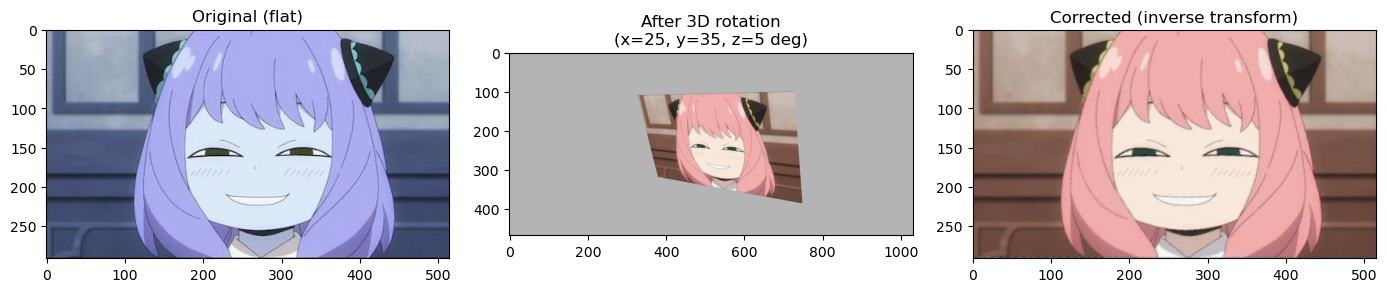

Mean pixel difference (original vs corrected): 32.27


True

In [18]:
# source = tilted corners, destination = perfect rectangle
H_correct = cv2.getPerspectiveTransform(tilted_pts, flat_pts)
corrected = cv2.warpPerspective(tilted, H_correct, (w, h))
 
# the correction matrix should be the inverse of the distortion matrix
check = H_correct @ H_distort
check = check / check[2, 2]
print("H_correct * H_distort (should be identity):\n", np.round(check, 3))
 
 
# ---------- show results ----------
#orig_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
tilted = cv2.cvtColor(tilted, cv2.COLOR_BGR2RGB)
corrected = cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB)
 
plt.figure(figsize=(14, 5))
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original (flat)")
plt.subplot(1, 3, 2)
plt.imshow(tilted)
plt.title(f"After 3D rotation\n(x={angle_x}, y={angle_y}, z={angle_z} deg)")
plt.subplot(1, 3, 3)
plt.imshow(corrected)
plt.title("Corrected (inverse transform)")
plt.tight_layout()
plt.show()
 
# Error between the original and corrected image
diff = np.mean(np.abs(img.astype(float) - corrected.astype(float)))
print("Mean pixel difference (original vs corrected):", round(diff, 2))

cv2.imwrite(os.path.join(OUT2, "tilted.jpg"), tilted)
cv2.imwrite(os.path.join(OUT2, "correct_3d_transformations.jpg"), corrected)